In [7]:
#STEP 1:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler,LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import(
    accuracy_score,
    confusion_matrix,
    classification_report
)
import warnings
warnings.filterwarnings('ignore')

In [8]:
#STEP 2
from sklearn.datasets import load_iris
iris=load_iris(as_frame=True)
df=iris.frame
print(df.head())
print("Shape:",df.shape)

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

   target  
0       0  
1       0  
2       0  
3       0  
4       0  
Shape: (150, 5)



Missing Values:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
target               0
dtype: int64

Target Distribution:
target
0    50
1    50
2    50
Name: count, dtype: int64


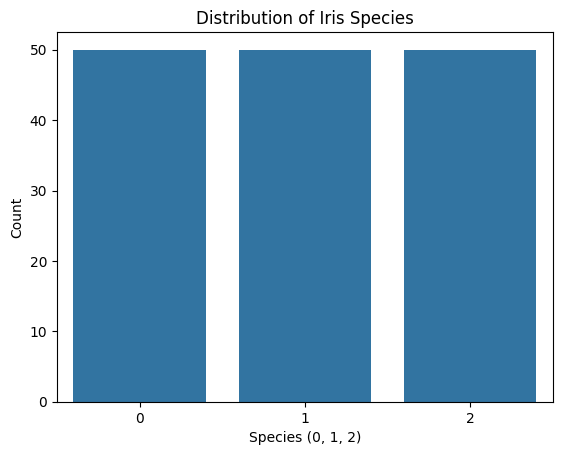

In [9]:
#STEP 3
print("\nMissing Values:")
print(df.isnull().sum())

# Check target class distribution
print("\nTarget Distribution:")
print(df['target'].value_counts())
sns.countplot(data=df, x='target')
plt.title("Distribution of Iris Species")
plt.xlabel("Species (0, 1, 2)")
plt.ylabel("Count")
plt.show()

In [10]:
# STEP 4
# Separate Features and Target
X = df.drop('target', axis=1)
y = df['target']

# Check missing values
print("Missing Values:")
print(X.isnull().sum())

# Handle missing values using SimpleImputer
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy='mean')
X = imputer.fit_transform(X)

# Display results
print("\nPreprocessing Completed Successfully!")
print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Missing Values:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
dtype: int64

Preprocessing Completed Successfully!
Features Shape: (150, 4)
Target Shape: (150,)


In [12]:
#step 5
# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Display dataset shapes
print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

print("Training Target Shape:", y_train.shape)
print("Testing Target Shape:", y_test.shape)

Training Data Shape: (120, 4)
Testing Data Shape: (30, 4)
Training Target Shape: (120,)
Testing Target Shape: (30,)


In [14]:
#STEP 6
# Create Naive Bayes Pipeline
model = Pipeline([
    ('imputer', SimpleImputer(strategy='mean')),
    ('classifier', GaussianNB())
])

print("Naive Bayes Pipeline Created Successfully!")
# Train the Naive Bayes model
model.fit(X_train, y_train)

print("Naive Bayes Model Trained Successfully!")

Naive Bayes Pipeline Created Successfully!
Naive Bayes Model Trained Successfully!


In [15]:
# STEP 7
# Predict using test data
y_pred = model.predict(X_test)

print("Actual Values:")
print(y_test.values)

print("\nPredicted Values:")
print(y_pred)

Actual Values:
[0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 2 2 1 1 0 2 0]

Predicted Values:
[0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 2 2 2 1 0 2 0]


In [16]:
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report

# Calculate Accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy * 100, "%")

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

print("\nConfusion Matrix:")
print(cm)

# Classification Report
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=iris.target_names
))

Model Accuracy: 96.66666666666667 %

Confusion Matrix:
[[10  0  0]
 [ 0  9  1]
 [ 0  0 10]]

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30

